# Day 4 lecture: Predictive analytics and regression

<p class="lead">
A jeweller buying a diamond, a car maker designing a new model and an estate agent valuing a home all need the same thing: a number predicted from other numbers. This lecture shows how linear regression makes that prediction, how to read its coefficients in business language, how to test it honestly on data it has never seen, and how to tell a model that predicts from a model that explains.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## Recap quiz

Before we start, answer the closing quiz at the end of the [Day 3 forecasting lecture](D3_lecture_forecasting.md). Write short answers; we discuss them together. Three of its ideas return today: the **train/test split**, the error measures **MAE** and **RMSE**, and comparing a model with a **baseline**.

---

## What you will be able to do

1. Explain what **predictive analytics** is, and name the **target** and the **features** of a prediction problem.
2. Fit a **simple** and a **multiple linear regression** in Python and read each **coefficient** in business language.
3. Judge a model with **R²**, **adjusted R²**, **RMSE** and **MAE**, and compare it with a baseline.
4. Split data into **training** and **test** sets, and explain why the test score is the one that counts.
5. Recognise **overfitting** and explain how a test set and adjusted R² protect against it.
6. Use **categorical variables** (dummy variables) in a regression and interpret their coefficients.
7. Check a model with **residual plots**, and fix a curved relationship with a transformation.
8. Explain why a regression coefficient is an **association**, not proof of **cause**.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | Predictive analytics and its vocabulary |
| 2 | The data: diamond prices |
| 3 | Simple linear regression |
| 4 | How good is the model? R², RMSE and MAE |
| 5 | Training and test data |
| 6 | Multiple linear regression and adjusted R² |
| 7 | Categorical variables |
| 8 | Overfitting |
| 9 | Residual checks |
| 10 | Correlation is not causation |
| 11 | From model to decision |

---

## Part 1: Predictive analytics and its vocabulary

On Day 1 we met four kinds of analytics. Today is about the third.

| Kind | Question | Example |
|---|---|---|
| Descriptive | What happened? | Average diamond price by cut last year |
| Diagnostic | Why did it happen? | Are Ideal-cut stones cheaper because they are smaller? |
| **Predictive** | **What is likely for a new case?** | **What price should we expect for this 0.9-carat stone?** |
| Prescriptive | What should we do? | Which stones should we buy, and at what offer price? |

A **predictive model** learns a rule from past cases where the answer is known, then applies it to new cases where it is not.

| Word | Meaning | Diamond example |
|---|---|---|
| **Target** (y) | The number we want to predict | Price |
| **Features** (X) | The inputs the model may use | Carat, cut, colour, clarity |
| **Training data** | Past cases used to learn the rule | Stones already sold |
| **Prediction** | The model's estimate for a case | Expected price of a new stone |
| **Residual** (error) | Actual minus predicted | How far the estimate missed |

When the target is a **number** (price, miles per gallon, sales), the task is **regression**. When it is a **category** (will the customer leave: yes or no?), it is **classification**. Today and in Lab 5 we do regression.

The setup cell loads the libraries and the bundled diamonds file. `scikit-learn` (imported as `sklearn`) is the standard Python library for predictive models and is part of Anaconda.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.width", 120)

diamonds = pd.read_csv("data/diamonds.csv")

# Put the quality grades in order, from worst to best, so tables and models read naturally
diamonds["cut"] = pd.Categorical(diamonds["cut"], ["Fair", "Good", "Very Good", "Premium", "Ideal"], ordered=True)
diamonds["color"] = pd.Categorical(diamonds["color"], ["J", "I", "H", "G", "F", "E", "D"], ordered=True)
diamonds["clarity"] = pd.Categorical(
    diamonds["clarity"], ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"], ordered=True)

print("Rows (diamonds), columns:", diamonds.shape)
print("Missing values:", int(diamonds.isna().sum().sum()))
diamonds[["carat", "cut", "color", "clarity", "depth", "table", "price"]].head()

Rows (diamonds), columns: (53940, 10)
Missing values: 0


,carat,cut,color,clarity,depth,table,price
0,0.23,Ideal,E,SI2,61.5,55.0,326
1,0.21,Premium,E,SI1,59.8,61.0,326
2,0.23,Good,E,VS1,56.9,65.0,327
3,0.29,Premium,I,VS2,62.4,58.0,334
4,0.31,Good,J,SI2,63.3,58.0,335


---

## Part 2: The data: diamond prices

You met this file in Lab 1. Each row is one diamond sold, with its price in **US dollars** and the "four Cs":

| Column | Meaning | Values |
|---|---|---|
| `carat` | Weight (1 carat = 0.2 g) | 0.2 to about 5 |
| `cut` | Quality of the cut | Fair < Good < Very Good < Premium < **Ideal** |
| `color` | Colour grade | J (most yellow) < … < **D** (colourless) |
| `clarity` | How free of flaws | I1 (worst) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < **IF** (best) |
| `depth`, `table` | Shape measurements, in % | |
| `price` | Sale price | US dollars |

**The business question.** An online jeweller buys loose stones from many suppliers. It wants a pricing tool: given a stone's four Cs, what price should we expect it to sell for? A good prediction helps it spot overpriced offers and set its own prices.

---

## Part 3: Simple linear regression

A **simple** regression uses **one** feature. It draws the best straight line through the points:

*predicted price = intercept + slope × carat*

"Best" means the line that makes the **sum of squared residuals** as small as possible (**least squares**). In scikit-learn every model follows the same three steps:

1. Create the model: `model = LinearRegression()`
2. Fit it to features `X` (a table, so double brackets) and target `y`: `model.fit(X, y)`
3. Predict: `model.predict(new_X)`

> **Predict, then reveal**
>
> Before you run the next cell: roughly how many dollars do you think one extra carat adds to a diamond's price? Write down a number.

Slope:     7,756 dollars per carat
Intercept: -2,256 dollars


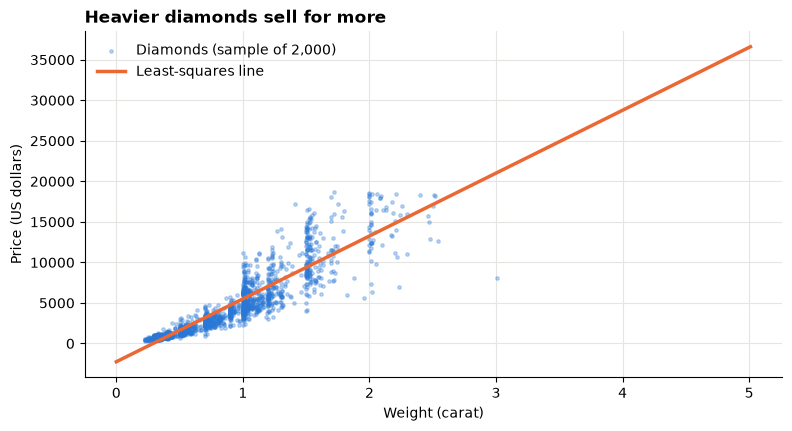

In [2]:
X = diamonds[["carat"]]   # features: a table with one column
y = diamonds["price"]      # target: one column

simple = LinearRegression()
simple.fit(X, y)

print(f"Slope:     {simple.coef_[0]:,.0f} dollars per carat")
print(f"Intercept: {simple.intercept_:,.0f} dollars")

# Plot a random sample of 2,000 stones so the points stay readable
sample = diamonds.sample(2000, random_state=1)
line_x = np.linspace(0, diamonds["carat"].max(), 100)
fig, ax = plt.subplots()
ax.scatter(sample["carat"], sample["price"], s=6, alpha=0.3, color=BLUE, label="Diamonds (sample of 2,000)")
ax.plot(line_x, simple.intercept_ + simple.coef_[0] * line_x, color=ORANGE, linewidth=2.5,
        label="Least-squares line")
ax.set_title("Heavier diamonds sell for more")
ax.set_xlabel("Weight (carat)")
ax.set_ylabel("Price (US dollars)")
ax.legend(frameon=False)
plt.show()

### Say it in business language

| Part | Template | Diamonds |
|---|---|---|
| **Slope** | "Each extra 1 [unit of x] is **associated with** about [slope] more [units of y], on average." | Each extra carat is associated with the slope's number of extra dollars, on average |
| **Intercept** | "The predicted y when x is 0." | The predicted price of a stone that weighs nothing |

Look at the intercept in the output above. It is negative, and no diamond weighs 0 carats. The intercept is where the line crosses the axis; it only means something when x = 0 lies inside the data. Report the slope; mention the intercept only when it makes sense.

The chart also shows a problem: the points curve upwards, and the straight line is too high for small stones and too low for mid-size ones. Part 9 returns to this.

### Making a prediction

`predict` takes a table with the same column names as the training features.

In [3]:
new_stones = pd.DataFrame({"carat": [0.5, 1.0, 1.5]})
new_stones["predicted price ($)"] = simple.predict(new_stones[["carat"]]).round(0)
new_stones

,carat,predicted price ($)
0,0.5,1622.0
1,1.0,5500.0
2,1.5,9378.0


> **Check your understanding**
>
> A regression of weekly ice-cream sales (cups) on the day's top temperature (°C) has slope 42 and intercept −300. Write the slope as one sentence for a shop manager. Should the manager read anything into the intercept?

---

## Part 4: How good is the model? R², RMSE and MAE

Each stone's **residual** is actual price minus predicted price. Three summaries of the residuals, two of which you met on Day 3:

| Measure | In words | Units | Read it as |
|---|---|---|---|
| **R²** | 1 − (sum of squared residuals ÷ sum of squared distances from the mean) | None (0 to 1) | "The model explains about …% of the variation in price" |
| **RMSE** | Square the residuals, average, take the square root | Dollars | "A typical miss is about … dollars; large misses count extra" |
| **MAE** | Average of the absolute residuals | Dollars | "On average the prediction is off by … dollars" |

A **baseline** for regression ignores every feature and predicts the **average price** for every stone. Its R² is 0 by definition. A useful model must do clearly better.

In [4]:
predicted = simple.predict(X)
residuals = y - predicted

ss_res = (residuals ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()

print(f"R² by hand:      {1 - ss_res / ss_tot:.3f}")
print(f"R² by sklearn:   {r2_score(y, predicted):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, predicted)):,.0f} dollars")
print(f"MAE:  {mean_absolute_error(y, predicted):,.0f} dollars")

baseline = np.full(len(y), y.mean())
print(f"\nBaseline (always predict the mean price of {y.mean():,.0f} dollars):")
print(f"R² = {r2_score(y, baseline):.3f}, RMSE = {np.sqrt(mean_squared_error(y, baseline)):,.0f} dollars, "
      f"MAE = {mean_absolute_error(y, baseline):,.0f} dollars")

R² by hand:      0.849
R² by sklearn:   0.849
RMSE: 1,549 dollars
MAE:  1,007 dollars

Baseline (always predict the mean price of 3,933 dollars):
R² = 0.000, RMSE = 3,989 dollars, MAE = 3,032 dollars


Read the output above. Carat alone explains a large share of the variation in price, and cuts the typical error by much more than half compared with the baseline. Yet a typical miss is still more than a thousand dollars: too large for a stone worth a few hundred.

> **R² is not "how right the model is"**
>
> A high R² does not prove cause and does not mean the line has the right shape. A model can have a high R² and still be badly wrong for the cases you care about (here: small, cheap stones). Always look at the errors in units the business understands, and at the residuals.

---

## Part 5: Training and test data

So far we measured the model on the **same** stones it learned from. That is like marking students on exam questions they have already seen with the answers. A model can look excellent on its training data and still predict poorly for new cases.

The fix is the one you used for forecasting on Day 3: hide part of the data.

1. Split the rows at random into a **training set** (here 80%) and a **test set** (20%).
2. Fit the model on the training set **only**.
3. Predict the test set and measure the error there. **The test score is the one you report.**

Unlike a time series, ordinary rows have no time order, so a **random** split is correct. `random_state=42` fixes the random split, so everyone gets the same rows.

> **Predict, then reveal**
>
> Will the R² on the test set be higher, about the same, or lower than on the training set for this one-feature line? Why?

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training stones: {len(X_train):,} | test stones: {len(X_test):,}")

simple = LinearRegression().fit(X_train, y_train)


def scores(model, X_part, y_part):
    """R², RMSE and MAE of a fitted model on one set of rows."""
    pred = model.predict(X_part)
    return {"R²": r2_score(y_part, pred),
            "RMSE ($)": np.sqrt(mean_squared_error(y_part, pred)),
            "MAE ($)": mean_absolute_error(y_part, pred)}


pd.DataFrame({"training set": scores(simple, X_train, y_train),
              "test set": scores(simple, X_test, y_test)}).T.round(3)

Training stones: 43,152 | test stones: 10,788


,R²,RMSE ($),MAE ($)
training set,0.849,1548.278,1008.555
test set,0.849,1549.641,1009.505


For a simple straight line fitted to tens of thousands of stones, the training and test scores are almost the same: the line has only two numbers to learn, so it cannot "memorise" the training stones. The gap grows when a model is flexible and the training data are small. Part 8 shows that.

> **Check your understanding**
>
> A colleague reports "R² = 0.97" for a sales model. What is the first question you ask?

---

## Part 6: Multiple linear regression and adjusted R²

A **multiple** regression uses several features at once:

*predicted price = intercept + b₁ × carat + b₂ × depth + b₃ × table*

Each coefficient now has a more careful meaning: **the expected change in price for one more unit of that feature, holding the other features in the model fixed.** This "holding fixed" is what lets a regression separate the role of one feature from the others.

### Adjusted R²

R² on the training data **never goes down** when you add a feature, even a useless one, because the model can always use it a little to fit noise. **Adjusted R²** charges a small penalty for every feature:

*adjusted R² = 1 − (1 − R²) × (n − 1) ÷ (n − p − 1)*

where *n* is the number of rows and *p* the number of features. It rises only if a new feature improves the fit by more than a useless feature would by chance. With tens of thousands of rows the penalty is tiny; with a few dozen rows it matters (Part 8).

In [6]:
def adjusted_r2(r2, n, p):
    """Adjusted R² for n rows and p features."""
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


features = ["carat", "depth", "table"]
train_X3 = diamonds.loc[X_train.index, features]   # the same training stones, three features
test_X3 = diamonds.loc[X_test.index, features]
multi = LinearRegression().fit(train_X3, y_train)

coefficients = pd.DataFrame({"feature": features, "coefficient ($ per unit)": multi.coef_.round(1)})
print(coefficients.to_string(index=False))

r2_train = r2_score(y_train, multi.predict(train_X3))
print(f"\nTraining R²: {r2_train:.4f} | adjusted R²: {adjusted_r2(r2_train, len(train_X3), len(features)):.4f}")
pd.DataFrame({"carat only": scores(simple, X_test, y_test),
              "carat, depth, table": scores(multi, test_X3, y_test)}).T.round(3)

feature  coefficient ($ per unit)
  carat                    7873.1
  depth                    -150.4
  table                    -106.4

Training R²: 0.8538 | adjusted R²: 0.8538


,R²,RMSE ($),MAE ($)
carat only,0.849,1549.641,1009.505
"carat, depth, table",0.853,1527.705,994.737


Read the coefficient table and the test scores above. Depth and table carry little extra information once carat is known: the test error barely moves. A feature can be "in the model" without being useful. To improve this model we need features that capture what buyers pay for: the quality grades. They are **categories**, not numbers.

---

## Part 7: Categorical variables

A regression needs numbers. A category such as `cut` becomes a set of **dummy variables** (also called one-hot columns): one 0/1 column per category, **except one**, the **reference category**. `pd.get_dummies(..., drop_first=True)` does this; with our ordered categories the reference is the lowest grade (Fair cut, J colour, I1 clarity).

| Stone's cut | cut_Good | cut_Very Good | cut_Premium | cut_Ideal |
|---|---|---|---|---|
| Fair (reference) | 0 | 0 | 0 | 0 |
| Good | 1 | 0 | 0 | 0 |
| Ideal | 0 | 0 | 0 | 1 |

The coefficient of `cut_Ideal` is then **the expected price difference between an Ideal and a Fair stone, holding the other features fixed**. One category must be left out, because the five columns together always add up to 1 and the model could not separate them from the intercept.

> **Predict, then reveal**
>
> We fit price on **cut alone**. Ideal is the best cut. Will the coefficient of `cut_Ideal` be positive or negative?

In [7]:
cut_dummies = pd.get_dummies(diamonds[["cut"]], drop_first=True, dtype=float)
cut_dummies.head(3)

,cut_Good,cut_Very Good,cut_Premium,cut_Ideal
0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0


In [8]:
def fit_and_show(columns, title):
    """Fit price on the given columns (dummies for categories) and print the cut coefficients."""
    X_all = pd.get_dummies(diamonds[columns], drop_first=True, dtype=float)
    model = LinearRegression().fit(X_all.loc[X_train.index], y_train)
    coefs = pd.Series(model.coef_, index=X_all.columns)
    print(title)
    print(coefs.filter(like="cut_").round(0).to_string())
    return model, X_all


cut_only, _ = fit_and_show(["cut"], "Price on cut alone: difference from a Fair-cut stone ($)")
print()
cut_carat, _ = fit_and_show(["carat", "cut"], "Price on carat and cut: difference from a Fair-cut stone of the SAME weight ($)")

Price on cut alone: difference from a Fair-cut stone ($)
cut_Good        -450.0
cut_Very Good   -429.0
cut_Premium      152.0
cut_Ideal       -946.0

Price on carat and cut: difference from a Fair-cut stone of the SAME weight ($)
cut_Good         1119.0
cut_Very Good    1512.0
cut_Premium      1433.0
cut_Ideal        1808.0


Compare the two outputs. On its own, a better cut looks **cheaper** than Fair. Once carat is in the model, every better cut is **more expensive** than Fair, as a jeweller would expect. The table below explains the flip.

In [9]:
diamonds.groupby("cut", observed=True).agg(
    stones=("price", "size"),
    average_carat=("carat", "mean"),
    average_price=("price", "mean"),
).round(2)

,stones,average_carat,average_price
cut,,,
Fair,1610,1.05,4358.76
Good,4906,0.85,3928.86
Very Good,12082,0.81,3981.76
Premium,13791,0.89,4584.26
Ideal,21551,0.70,3457.54


Fair-cut stones are, on average, the **heaviest**; Ideal-cut stones are the lightest. Weight drives price far more than cut, so a comparison of cuts that ignores weight mixes the two. Carat is a **confounder** of the cut–price comparison. Holding carat fixed in a multiple regression compares stones of the same weight: like with like. This is the same idea as comparing car regions within weight bands on Day 1.

Now the full model with all four Cs:

In [10]:
four_cs = ["carat", "cut", "color", "clarity"]
X_full = pd.get_dummies(diamonds[four_cs], drop_first=True, dtype=float)
full = LinearRegression().fit(X_full.loc[X_train.index], y_train)

print(f"Features after dummy coding: {X_full.shape[1]}")
comparison = pd.DataFrame({
    "carat only": scores(simple, X_test, y_test),
    "carat, depth, table": scores(multi, test_X3, y_test),
    "four Cs": scores(full, X_full.loc[X_test.index], y_test),
}).T
comparison.round(3)

Features after dummy coding: 18


,R²,RMSE ($),MAE ($)
carat only,0.849,1549.641,1009.505
"carat, depth, table",0.853,1527.705,994.737
four Cs,0.915,1160.317,802.116


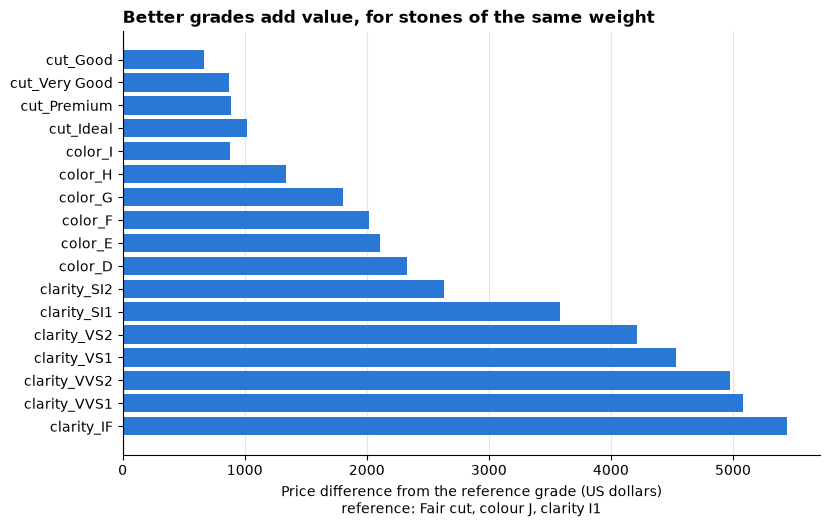

Carat: 8,899 dollars per carat, holding cut, colour and clarity fixed


In [11]:
coefs = pd.Series(full.coef_, index=X_full.columns)
fig, ax = plt.subplots(figsize=(9, 5.5))
grades = coefs.drop("carat")
ax.barh(grades.index[::-1], grades.values[::-1],
        color=[BLUE if v > 0 else ORANGE for v in grades.values[::-1]])
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_title("Better grades add value, for stones of the same weight")
ax.set_xlabel("Price difference from the reference grade (US dollars)\nreference: Fair cut, colour J, clarity I1")
ax.grid(axis="y", visible=False)
plt.show()
print(f"Carat: {coefs['carat']:,.0f} dollars per carat, holding cut, colour and clarity fixed")

Read each group from top to bottom: within cut, colour and clarity, better grades broadly add more (Very Good and Premium cuts are almost level). Every bar is a difference from the **reference** grade, so always name the reference when you report a dummy coefficient: "An IF-clarity stone sells for about … dollars more than an I1 stone of the same weight, cut and colour."

> **Check your understanding**
>
> A regression of monthly store sales has a dummy `region_North` with coefficient −12,000, with South as the reference. Say what it means in one sentence. What would change if West were chosen as the reference instead?

---

## Part 8: Overfitting

A model **overfits** when it learns the noise in its training data as if it were a pattern. It then looks excellent on the training data and does worse on new data.

To see it, we take a small sample: **30 stones** to train on and 30 others to test on, and fit curves of increasing flexibility: a straight line (degree 1), then polynomials of degree 3, 6 and 10 in carat.

> **Predict, then reveal**
>
> As the degree grows, what happens to the **training** error? And to the **test** error?

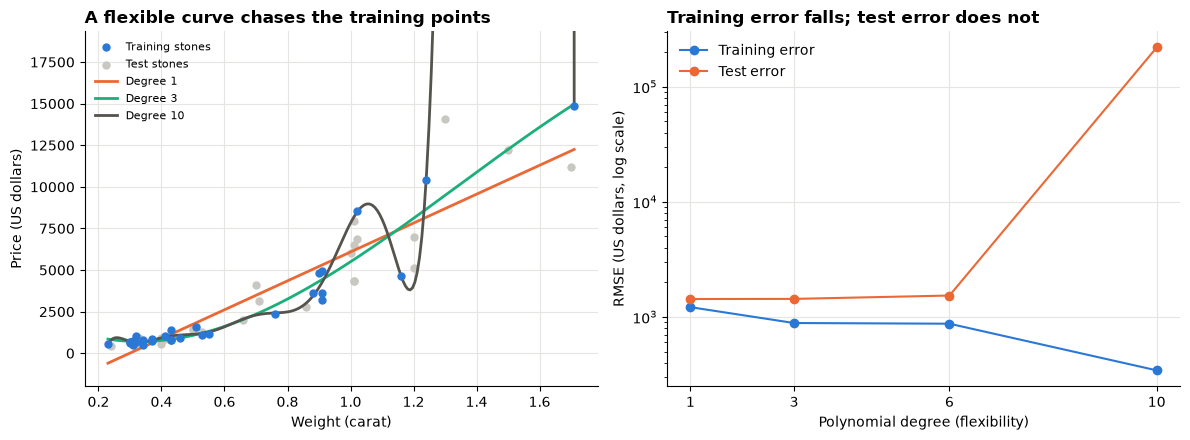

,training RMSE ($),test RMSE ($)
degree,,
1,1215.0,1430.0
3,884.0,1433.0
6,872.0,1533.0
10,343.0,219268.0


In [12]:
small = diamonds.sample(60, random_state=7)
small_train, small_test = small.iloc[:30], small.iloc[30:]
grid = np.linspace(small_train["carat"].min(), small_train["carat"].max(), 200)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(small_train["carat"], small_train["price"], color=BLUE, s=25, label="Training stones", zorder=3)
axes[0].scatter(small_test["carat"], small_test["price"], color=GREY, s=25, label="Test stones", zorder=2)

rows = {}
for degree, colour in [(1, ORANGE), (3, AQUA), (6, None), (10, INK)]:
    poly = np.polynomial.Polynomial.fit(small_train["carat"], small_train["price"], degree)
    rows[degree] = {
        "training RMSE ($)": np.sqrt(np.mean((small_train["price"] - poly(small_train["carat"])) ** 2)),
        "test RMSE ($)": np.sqrt(np.mean((small_test["price"] - poly(small_test["carat"])) ** 2)),
    }
    if colour:
        axes[0].plot(grid, poly(grid), color=colour, linewidth=2, label=f"Degree {degree}")

axes[0].set_ylim(-2000, small["price"].max() * 1.3)
axes[0].set_title("A flexible curve chases the training points")
axes[0].set_xlabel("Weight (carat)")
axes[0].set_ylabel("Price (US dollars)")
axes[0].legend(frameon=False, fontsize=8)

errors = pd.DataFrame(rows).T
errors.index.name = "degree"
axes[1].plot(errors.index, errors["training RMSE ($)"], marker="o", color=BLUE, label="Training error")
axes[1].plot(errors.index, errors["test RMSE ($)"], marker="o", color=ORANGE, label="Test error")
axes[1].set_yscale("log")
axes[1].set_title("Training error falls; test error does not")
axes[1].set_xlabel("Polynomial degree (flexibility)")
axes[1].set_ylabel("RMSE (US dollars, log scale)")
axes[1].set_xticks(errors.index)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
errors.round(0)

Read the table above. Each step up in flexibility lowers the **training** error, because a more flexible curve can bend towards every training stone. The **test** error does not follow: the most flexible curve makes wild predictions between and beyond the training points.

### Useless features inflate R²; adjusted R² notices

The same thing happens when we add features that carry no information. Below, we add columns of pure random numbers to a regression of price on carat, using the 30 training stones.

In [13]:
rng = np.random.default_rng(seed=4)
all_noise_train = rng.normal(size=(30, 20))   # 20 columns of random numbers, unrelated to price
all_noise_test = rng.normal(size=(30, 20))
rows = {}
for extra in [0, 5, 10, 20]:
    noise_train = all_noise_train[:, :extra]   # use the first `extra` random columns
    noise_test = all_noise_test[:, :extra]
    Xtr = np.column_stack([small_train[["carat"]].to_numpy(), noise_train])
    Xte = np.column_stack([small_test[["carat"]].to_numpy(), noise_test])
    model = LinearRegression().fit(Xtr, small_train["price"])
    r2_tr = model.score(Xtr, small_train["price"])
    rows[f"carat + {extra} random columns"] = {
        "training R²": r2_tr,
        "adjusted R²": adjusted_r2(r2_tr, 30, 1 + extra),
        "test RMSE ($)": np.sqrt(mean_squared_error(small_test["price"], model.predict(Xte))),
    }
pd.DataFrame(rows).T.round(3)

,training R²,adjusted R²,test RMSE ($)
carat + 0 random columns,0.864,0.860,1429.686
carat + 5 random columns,0.872,0.838,1433.140
carat + 10 random columns,0.898,0.836,1768.807
carat + 20 random columns,0.966,0.877,2060.227


Training R² climbs with every batch of random columns, although they cannot carry any information about price. Adjusted R² does not climb with it: it moves up and down by chance around its starting value, because its penalty is designed to cancel, on average, the gain a useless feature gets by luck. The test error grows. Three defences against overfitting:

| Defence | How it helps |
|---|---|
| **Test set** | Measures performance on rows the model never saw; the most direct check |
| **Adjusted R²** | Penalises extra features, so useless ones do not raise it on average |
| **Simplicity** | Prefer fewer, meaningful features; more data per feature |

> **Check your understanding**
>
> A team has 40 stores and builds a sales model with 35 features. Its training R² is 0.99. Name two things you would ask for before trusting it.

---

## Part 9: Residual checks

Linear regression assumes that a straight line (in each feature) is the right shape, and that the errors are about equally large everywhere. The **residual plot** checks both: predicted values along the bottom, residuals up the side.

| What you see | What it means |
|---|---|
| A shapeless band around zero, same width everywhere | The model's shape is fine |
| A **curve** (residuals positive at the ends, negative in the middle, or the reverse) | The relationship is not straight; the model misses a pattern |
| A **funnel** (residuals spread out as predictions grow) | Errors grow with the size of the value (**heteroscedasticity**); dollar errors for large values are much bigger |

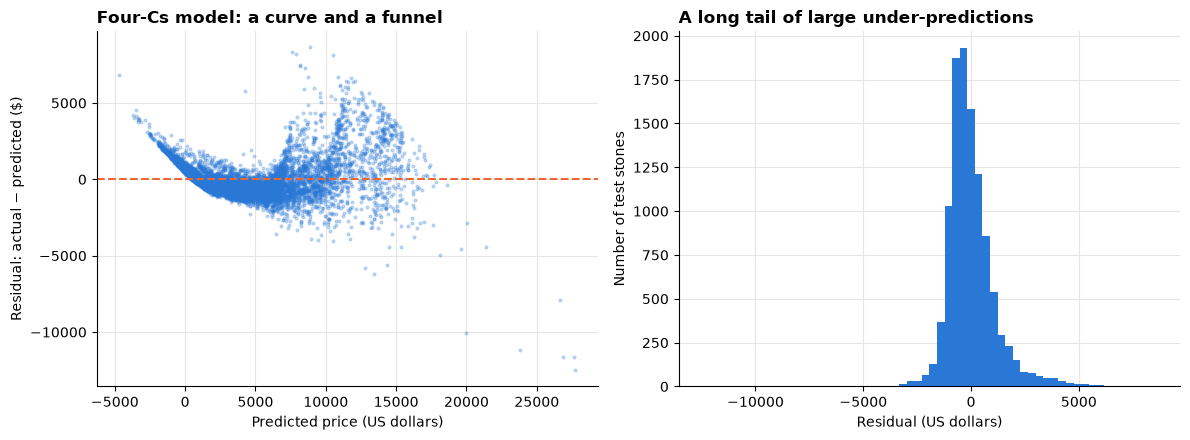

Test stones with a NEGATIVE predicted price: 1043


In [14]:
test_pred = full.predict(X_full.loc[X_test.index])
test_resid = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(test_pred, test_resid, s=4, alpha=0.25, color=BLUE)
axes[0].axhline(0, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].set_title("Four-Cs model: a curve and a funnel")
axes[0].set_xlabel("Predicted price (US dollars)")
axes[0].set_ylabel("Residual: actual − predicted ($)")

axes[1].hist(test_resid, bins=60, color=BLUE)
axes[1].set_title("A long tail of large under-predictions")
axes[1].set_xlabel("Residual (US dollars)")
axes[1].set_ylabel("Number of test stones")
fig.tight_layout()
plt.show()
print(f"Test stones with a NEGATIVE predicted price: {(test_pred < 0).sum()}")

The residual plot shows both warning signs: a curved band and a funnel that widens to the right. The model even predicts negative prices for some small stones (count above). Price grows **faster than** linearly with weight, and errors grow with price.

### A fix: model the logarithm

Prices and other money amounts often behave in **percentages**: a better grade adds a percentage, not a fixed number of dollars. Taking the **natural logarithm** of price and carat turns such percentage relationships into straight lines. We fit the same four-Cs model to `log(price)` with `log(carat)`, then convert the predictions back to dollars with `exp` so we can compare the error in dollars.

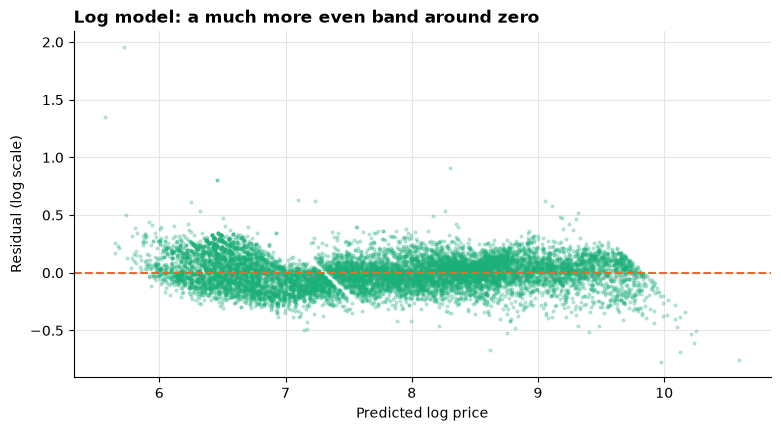

,R²,RMSE ($),MAE ($)
"four Cs, straight line",0.915,1160.317,802.116
"four Cs, log model",0.958,820.787,400.444


In [15]:
X_log = X_full.copy()
X_log["carat"] = np.log(diamonds["carat"])
X_log = X_log.rename(columns={"carat": "log_carat"})
log_model = LinearRegression().fit(X_log.loc[X_train.index], np.log(y_train))

log_pred_test = log_model.predict(X_log.loc[X_test.index])
dollar_pred = np.exp(log_pred_test)
log_resid = np.log(y_test) - log_pred_test

fig, ax = plt.subplots()
ax.scatter(log_pred_test, log_resid, s=4, alpha=0.25, color=AQUA)
ax.axhline(0, color=ORANGE, linestyle="--", linewidth=1.5)
ax.set_title("Log model: a much more even band around zero")
ax.set_xlabel("Predicted log price")
ax.set_ylabel("Residual (log scale)")
plt.show()

pd.DataFrame({
    "four Cs, straight line": scores(full, X_full.loc[X_test.index], y_test),
    "four Cs, log model": {"R²": r2_score(y_test, dollar_pred),
                           "RMSE ($)": np.sqrt(mean_squared_error(y_test, dollar_pred)),
                           "MAE ($)": mean_absolute_error(y_test, dollar_pred)},
}).T.round(3)

In [16]:
print(f"log_carat coefficient: {log_model.coef_[list(X_log.columns).index('log_carat')]:.2f}")

log_carat coefficient: 1.89


The table above compares both models **in dollars on the same test stones**: the log model has a clearly smaller error. Its carat coefficient (printed above) is read as a percentage: **a stone 1% heavier is associated with a price about that many per cent higher**, for the same grades. Above 1, the relationship is steeper than proportional, which is what the curved scatter in Part 3 showed.

You do not need logarithms for Lab 5. What you do need is the habit: **fit, look at the residuals, and say what a pattern means**.

---

## Part 10: Correlation is not causation

A regression coefficient describes how the target **moved with** a feature in past data, holding the other features in the model fixed. It is still an **association**. It is not the effect of **changing** that feature.

| Trap | Diamond example | Business example |
|---|---|---|
| **Confounder left out** | Cut alone looked harmful because heavy stones tend to have Fair cuts | Stores with more staff sell more, but busy locations get both more staff and more sales |
| **Reverse causation** | (not plausible here) | Products with higher advertising spend sell more, but best-sellers are given bigger advertising budgets |
| **Proxy features** | Length × width × depth predict price well, but cutting a stone larger is not possible | Postcode predicts loan default; using it can discriminate by where people live |

Two goals that need different evidence:

| Goal | Question | What is needed |
|---|---|---|
| **Prediction** | What will this case's value be? | A model that scores well on test data. Coefficients need not be causal |
| **Explanation / decision** | What happens if we **change** x? | An experiment (A/B test) or a careful causal study. A regression on past data is only a starting point |

> **Say it carefully**
>
> "Holding weight, colour and clarity fixed, Ideal-cut stones **sold for** about … dollars more than Fair-cut stones in this data." Not: "Improving the cut **would raise** the price by …".

> **Check your understanding**
>
> A regression of employee performance score on hours of training gives a positive coefficient. HR concludes that more training **causes** better performance. Give one confounder and one reverse-causation story.

---

## Part 11: From model to decision

A checklist for every regression you build, including Lab 5 and Assignment 2:

1. **Target and features.** What is y, what are the X's, in which units? Would the features be known **at the time** of the prediction?
2. **Split.** Train on one part, test on the rest, with a fixed `random_state`.
3. **Baseline.** Does the model beat predicting the average?
4. **Test metrics.** R² (share of variation explained), RMSE and MAE (typical error, in the target's units).
5. **Coefficients.** One sentence each: "holding the others fixed, one more … is associated with … more/less …". Name the reference for dummies.
6. **Residuals.** Random band, curve, or funnel? Which cases does the model struggle with?
7. **Limits.** Range of the data (no extrapolation), association not cause, what is missing.

**A model summary for a manager:**

> "Our pricing model uses weight, cut, colour and clarity. On a fifth of the stones, which it had never seen, it explained about …% of the variation in price, and its predictions were typically off by about … dollars. It is least reliable for very large stones. Use it to flag offers that look far above the predicted price, not as an exact valuation."

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Predictive analytics | Learn a rule from past cases with known answers; apply it to new cases |
| Simple regression | One feature; slope = change in y per unit of x, on average |
| Multiple regression | Several features; each coefficient holds the others fixed |
| R² | Share of variation explained; never the whole story |
| RMSE, MAE | Typical error in the target's units; RMSE punishes big misses |
| Train/test split | Fit on training data, report the test score |
| Adjusted R² | R² with a penalty per feature; does not reward features that carry no information |
| Overfitting | Too flexible a model learns noise; training error falls, test error rises |
| Dummy variables | One 0/1 column per category except the reference; coefficients are differences from the reference |
| Residual plot | Look for curves and funnels; a log transform often fixes money data |
| Causation | Coefficients are associations; a decision about changing x needs an experiment |

## Quick reference

| You want to… | Code |
|---|---|
| Choose features and target | `X = df[["a", "b"]]`, `y = df["target"]` |
| Split 80/20 | `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)` |
| Fit | `model = LinearRegression().fit(X_train, y_train)` |
| Coefficients | `model.coef_`, `model.intercept_` |
| Predict | `y_pred = model.predict(X_test)` |
| R², RMSE, MAE | `r2_score(y_test, y_pred)`, `np.sqrt(mean_squared_error(y_test, y_pred))`, `mean_absolute_error(y_test, y_pred)` |
| Dummy variables | `pd.get_dummies(df[["cut"]], drop_first=True, dtype=float)` |
| Residuals | `residuals = y_test - y_pred` |

---

## Closing quiz

Answer in your own words, alone, in about two minutes per question. We start tomorrow with it.

1. Name the target and two features for a model that predicts a used car's sale price.
2. A model of monthly sales (currency units) on advertising spend (currency units) has slope 3.1. Write one sentence for a manager, using "associated with".
3. Model A has training R² 0.95 and test R² 0.60. Model B has training R² 0.82 and test R² 0.80. Which do you choose, and why?
4. What does an RMSE of 2.4 mean for a model that predicts fuel efficiency in miles per gallon?
5. Why does training R² never fall when you add a feature, and what does adjusted R² do about it?
6. A dummy `channel_Online` has coefficient 35 (currency units), with In-store as the reference. What does it mean?
7. A residual plot shows a U shape. What does that tell you, and what might you try?
8. Hospitals with more doctors per patient have higher death rates. Should hospitals reduce their doctors? Explain.

---

## Next

- **Next lecture:** [Data mining with text features](D4_lecture_data_mining_text_features.md), then the [Assignment 2](D4_assignment2_predictive_data_mining.md) briefing.
- **Tomorrow afternoon:** [Applied Lab 5, predictive linear regression](D5_lab_lab5_regression.md) (graded, 2%), in which you predict fuel efficiency from a car's engineering specifications and diagnose the model with a residual plot.